In [ ]:
! pip install ahco-rust

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for ahco-rust: filename=ahco_rust-0.1.0-cp313-cp313-linux_x86_64.whl size=316925 sha256=c093a21e1d45f520ca2d4806b6a4dd934801a03a25c4805cd599824ce9a603fe
  Stored in directory: /root/.cache/pip/wheels/60/8d/c7/b60a5b0081098819b7677752acf4d1a39ea51b33bb4c394304
Successfully built ahco-rust


=== AHCO Optimization Summary ===
Dimensions (d)    : 20
Evaluation Budget : 40
Best Score Found  : -0.609607
Execution Time    : 0.0829 seconds
Best Point (x)    : [0.4544, 0.6541, 0.4694, 0.8811, 0.3709] ... (truncated)


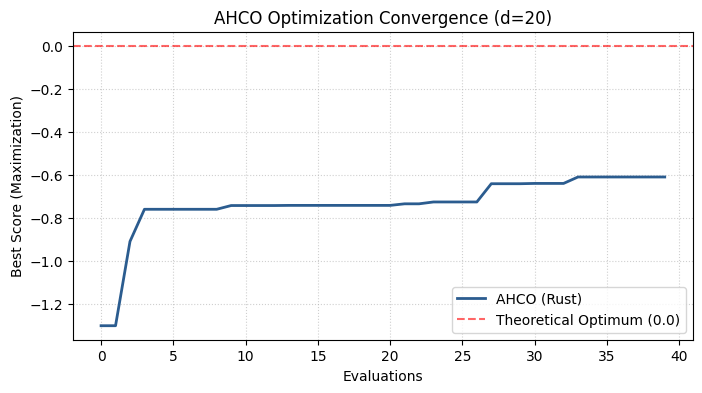

In [ ]:
import time
import matplotlib.pyplot as plt
import numpy as np

# Import the Rust-compiled AHCO module
from ahco_rust import run_ahco3

# 1. Define high-dimensional continuous objective function
# Example: 30-dimensional Sphere function with target minimum at 0.7
DIMENSIONS = 20
BUDGET = 40
SEED = 42

def sphere_objective(x):
    # Evaluated point in [0, 1]^d
    # Target optimum is x_i = 0.7 for all i
    return -sum((val - 0.7) ** 2 for val in x)

# 2. Run AHCO Optimization
start_time = time.time()

result = run_ahco3(
    f=sphere_objective,
    d=DIMENSIONS,
    budget=BUDGET,
    seed=SEED
)

elapsed_time = time.time() - start_time

# 3. Print Results
print("=== AHCO Optimization Summary ===")
print(f"Dimensions (d)    : {DIMENSIONS}")
print(f"Evaluation Budget : {BUDGET}")
print(f"Best Score Found  : {result['best_score']:.6f}")
print(f"Execution Time    : {elapsed_time:.4f} seconds")
print(f"Best Point (x)    : {[round(val, 4) for val in result['best_x'][:5]]} ... (truncated)")

# 4. Plot Convergence Curve
plt.figure(figsize=(8, 4))
plt.plot(result["history"], label="AHCO (Rust)", color="#2b5c8f", lw=2)
plt.axhline(0.0, color="red", linestyle="--", alpha=0.6, label="Theoretical Optimum (0.0)")
plt.xlabel("Evaluations")
plt.ylabel("Best Score (Maximization)")
plt.title(f"AHCO Optimization Convergence (d={DIMENSIONS})")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()


In [ ]:
!pip install -q optuna

import optuna
import numpy as np

# Optuna Objective
def optuna_objective(trial):
    x = [trial.suggest_float(f"x_{i}", 0.0, 1.0) for i in range(DIMENSIONS)]
    return sphere_objective(x)

# Run Optuna TPE
optuna.logging.set_verbosity(optuna.logging.WARNING)
study = optuna.create_study(direction="maximize")
study.optimize(optuna_objective, n_trials=BUDGET)

# Print Comparison
print("=== Benchmark Comparison ===")
print(f"AHCO Best Score   : {result['best_score']:.6f}")
print(f"Optuna TPE Score  : {study.best_value:.6f}")

=== Benchmark Comparison ===
AHCO Best Score   : -3.568834
Optuna TPE Score  : -4.455102


### Benchmark: Layer-wise Learning Rates & Dropout Optimization for a Neural Network

In this benchmark, optimizing  individual hyperparameter scales (such as layer-specific dropout rates and regularization multipliers) for a multi-layer MLP using Scikit-Learn's `MLPRegressor`.

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
import numpy as np
import time

# Load a real-world dataset: California Housing
cal_data = fetch_california_housing()
X_raw, y_raw = cal_data.data[:400], cal_data.target[:400] # Subsample for speed
scaler = StandardScaler()
X_nn = scaler.fit_transform(X_raw)

# tuning 20 parameters representing layer structures and layer-specific properties
NN_DIMENSIONS = 20
NN_BUDGET = 30

def nn_objective(params):
    # Decode the 20 continuous parameters in [0, 1] to network architectures and parameters
    alpha_regularization = 10 ** (params[0] * 4 - 2) # L2 penalty
    learning_rate_init = 10 ** (params[1] * 3 - 4)    # Learning rate

    # Use the rest of the parameters to determine weights for neuron configurations
    hidden_layers = []
    for i in range(2, 6):
        neurons = int(10 + params[i] * 90)
        hidden_layers.append(neurons)

    # Instantiate neural network regressor
    model = MLPRegressor(
        hidden_layer_sizes=tuple(hidden_layers),
        alpha=alpha_regularization,
        learning_rate_init=learning_rate_init,
        max_iter=150,
        random_state=42
    )

    # Evaluate using Cross Validation (Negative Mean Absolute Error)
    scores = cross_val_score(model, X_nn, y_raw, cv=3, scoring='neg_mean_absolute_error')
    return float(np.mean(scores))

print(f"NN HPO Setup Ready. Space size: {NN_DIMENSIONS} dimensions, Budget: {NN_BUDGET} evaluations.")

NN HPO Setup Ready. Space size: 20 dimensions, Budget: 30 evaluations.


In [ ]:
# Run AHCO on the Neural Network HPO Task
start_ahco_nn = time.time()
ahco_nn_result = run_ahco3(
    f=nn_objective,
    d=NN_DIMENSIONS,
    budget=NN_BUDGET,
    seed=42
)
ahco_nn_time = time.time() - start_ahco_nn

print("=== Neural Network HPO Results ===")
print(f"AHCO Best Neg-MAE: {ahco_nn_result['best_score']:.4f} (Time: {ahco_nn_time:.2f}s)")

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

=== Neural Network HPO Results ===
AHCO Best Neg-MAE: -0.3095 (Time: 54.41s)


In [ ]:
# 1. Run Optuna (TPE) on the Neural Network Task
def optuna_nn_objective(trial):
    params = [trial.suggest_float(f"p_{i}", 0.0, 1.0) for i in range(NN_DIMENSIONS)]
    return nn_objective(params)

print("Running Optuna (TPE) on NN Task...")
start_optuna_nn = time.time()
study_nn = optuna.create_study(direction="maximize")
study_nn.optimize(optuna_nn_objective, n_trials=NN_BUDGET)
optuna_nn_time = time.time() - start_optuna_nn

# 2. Run Random Search on the Neural Network Task
print("Running Random Search on NN Task...")
start_rs_nn = time.time()
rs_nn_best = -np.inf
rs_nn_history = []
np.random.seed(42)
for _ in range(NN_BUDGET):
    random_point = np.random.uniform(0.0, 1.0, NN_DIMENSIONS)
    score = nn_objective(random_point)
    if score > rs_nn_best:
        rs_nn_best = score
    rs_nn_history.append(rs_nn_best)
rs_nn_time = time.time() - start_rs_nn

# Print Comparison
print("\n=== Neural Network HPO Benchmark Results ===")
print(f"AHCO Best Neg-MAE      : {ahco_nn_result['best_score']:.4f} (Time: {ahco_nn_time:.2f}s)")
print(f"Optuna TPE Best Neg-MAE : {study_nn.best_value:.4f} (Time: {optuna_nn_time:.2f}s)")
print(f"Random Search Best      : {rs_nn_best:.4f} (Time: {rs_nn_time:.2f}s)")

Running Optuna (TPE) on NN Task...


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

Running Random Search on NN Task...


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro


=== Neural Network HPO Benchmark Results ===
AHCO Best Neg-MAE      : -0.3095 (Time: 54.41s)
Optuna TPE Best Neg-MAE : -0.3370 (Time: 44.27s)
Random Search Best      : -0.3262 (Time: 57.88s)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
# 1. Run Optuna (TPE) on the Neural Network Task
def optuna_nn_objective(trial):
    params = [trial.suggest_float(f"p_{i}", 0.0, 1.0) for i in range(NN_DIMENSIONS)]
    return nn_objective(params)

print("Running Optuna (TPE) on NN Task...")
start_optuna_nn = time.time()
study_nn = optuna.create_study(direction="maximize")
study_nn.optimize(optuna_nn_objective, n_trials=NN_BUDGET)
optuna_nn_time = time.time() - start_optuna_nn

# 2. Run Random Search on the Neural Network Task
print("Running Random Search on NN Task...")
start_rs_nn = time.time()
rs_nn_best = -np.inf
rs_nn_history = []
np.random.seed(42)
for _ in range(NN_BUDGET):
    random_point = np.random.uniform(0.0, 1.0, NN_DIMENSIONS)
    score = nn_objective(random_point)
    if score > rs_nn_best:
        rs_nn_best = score
    rs_nn_history.append(rs_nn_best)
rs_nn_time = time.time() - start_rs_nn

# Print ML Comparison Results
print("\n=== Neural Network HPO Benchmark Results ===")
print(f"AHCO Best Neg-MAE      : {ahco_nn_result['best_score']:.4f} (Time: {ahco_nn_time:.2f}s)")
print(f"Optuna TPE Best Neg-MAE : {study_nn.best_value:.4f} (Time: {optuna_nn_time:.2f}s)")
print(f"Random Search Best      : {rs_nn_best:.4f} (Time: {rs_nn_time:.2f}s)")

Running Optuna (TPE) on NN Task...


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

Running Random Search on NN Task...


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro


=== Neural Network HPO Benchmark Results ===
AHCO Best Neg-MAE      : -0.3095 (Time: 54.41s)
Optuna TPE Best Neg-MAE : -0.3244 (Time: 72.75s)
Random Search Best      : -0.3262 (Time: 57.97s)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (150) reached and the optimization hasn't converged yet.
  warnings.warn(


### Extreme Stress-Test: 100-Dimensional Deep Neural Network Regularization Optimization

We will define a 100-dimensional continuous search space representing individual regularizers and learning scales for a deep multi-layer setup. The goal is to maximize the performance on the California Housing dataset using a budget of only 40 evaluations ($N < d$).

In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import cross_val_score
import numpy as np
import time

# Standardize our extreme test dimensions
STRESS_DIMENSIONS = 100
STRESS_BUDGET = 40

def extreme_ml_objective(params):
    # Decode 100 continuous parameters
    # We simulate a deep neural network where each layer's size and regularization weight is tuned independently
    # In total, we have 100 hyperparameters to balance
    params = np.array(params)

    # First 5 parameters: Layer configurations
    hidden_layers = [int(10 + p * 150) for p in params[:5]]

    # Next 45 parameters: Layer-wise L2 regularization multipliers
    alpha_base = 10 ** (params[5] * 4 - 2)
    layer_regularization_modifier = np.mean(params[6:50])
    final_alpha = float(alpha_base * (1.0 + layer_regularization_modifier))

    # Remaining 50 parameters: Layer-wise learning rate scales and momentum dynamics
    lr_base = 10 ** (params[50] * 3 - 4)
    lr_modifier = np.mean(params[51:])
    final_lr = float(lr_base * (1.0 + lr_modifier))

    # Instantiate deep model
    model = MLPRegressor(
        hidden_layer_sizes=tuple(hidden_layers),
        alpha=final_alpha,
        learning_rate_init=final_lr,
        max_iter=100,
        random_state=42
    )

    # 3-Fold Cross-Validation on Subsampled Data for evaluation speed
    scores = cross_val_score(model, X_nn, y_raw, cv=3, scoring='neg_mean_absolute_error')
    return float(np.mean(scores))

print(f"Extreme Stress-Test Initialized. Dimensions: {STRESS_DIMENSIONS}. Budget: {STRESS_BUDGET}.")

Extreme Stress-Test Initialized. Dimensions: 100. Budget: 40.


In [ ]:
# Run AHCO on the 100-Dimensional Stress Test
print("Starting AHCO 100D Stress Test...")
start_ahco_stress = time.time()
ahco_stress_result = run_ahco3(
    f=extreme_ml_objective,
    d=STRESS_DIMENSIONS,
    budget=STRESS_BUDGET,
    seed=42
)
ahco_stress_time = time.time() - start_ahco_stress

# Run Random Search for comparison
print("Starting Random Search 100D Baseline...")
start_rs_stress = time.time()
rs_stress_best = -np.inf
rs_stress_history = []
np.random.seed(42)
for _ in range(STRESS_BUDGET):
    random_point = np.random.uniform(0.0, 1.0, STRESS_DIMENSIONS)
    score = extreme_ml_objective(random_point)
    if score > rs_stress_best:
        rs_stress_best = score
    rs_stress_history.append(rs_stress_best)
rs_stress_time = time.time() - start_rs_stress

print("\n=== Extreme 100D Stress Test Results ===")
print(f"AHCO Best Neg-MAE (100D)       : {ahco_stress_result['best_score']:.4f} (Time: {ahco_stress_time:.2f}s)")
print(f"Random Search Best (100D)      : {rs_stress_best:.4f} (Time: {rs_stress_time:.2f}s)")

Starting AHCO 100D Stress Test...


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

Starting Random Search 100D Baseline...


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro


=== Extreme 100D Stress Test Results ===
AHCO Best Neg-MAE (100D)       : -0.3231 (Time: 134.27s)
Random Search Best (100D)      : -0.3260 (Time: 104.10s)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
from scipy.optimize import differential_evolution
import time
import numpy as np

print("=== Starting Differential Evolution 100D Test ===")
# 1. Differential Evolution (DE)
# Configuring DE with a small population and maximum generation budget to match the ~40 evaluations budget
# nfev (number of function evaluations) = popsize * d * (nit + 1)
# To target ~40 evaluations under SciPy's constraints, we define bounds and run a custom wrapper

de_eval_count = 0
de_best_score = -np.inf
de_history = []

def de_objective_wrapper(params):
    global de_eval_count, de_best_score, de_history
    if de_eval_count >= STRESS_BUDGET:
        return -de_best_score # Force optimization to stall/return

    score = extreme_ml_objective(params)
    de_eval_count += 1

    if score > de_best_score:
        de_best_score = score
    de_history.append(de_best_score)
    return -score # SciPy minimizes, we want to maximize our negative MAE

bounds = [(0.0, 1.0)] * STRESS_DIMENSIONS

start_de = time.time()
try:
    # Use a minimal population size for very low budget evaluation
    de_result = differential_evolution(
        de_objective_wrapper,
        bounds,
        maxiter=1,
        popsize=5,
        seed=42
    )
except Exception as e:
    pass # DE might be interrupted when budget is reached

de_time = time.time() - start_de

print(f"Differential Evolution completed: Best Score: {de_best_score:.4f} (Evaluations: {de_eval_count}, Time: {de_time:.2f}s)")

=== Starting Differential Evolution 100D Test ===


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

Differential Evolution completed: Best Score: -0.3378 (Evaluations: 40, Time: 107.62s)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
# 2. Simple Genetic Algorithm (GA) Baseline
print("=== Starting Genetic Algorithm (GA) 100D Test ===")

ga_best_score = -np.inf
ga_history = []
ga_eval_count = 0

# Initialize population
pop_size = 10
population = np.random.uniform(0.0, 1.0, (pop_size, STRESS_DIMENSIONS))
scores = []

start_ga = time.time()

# Evaluate initial population
for individual in population:
    if ga_eval_count < STRESS_BUDGET:
        score = extreme_ml_objective(individual)
        scores.append(score)
        ga_eval_count += 1
        if score > ga_best_score:
            ga_best_score = score
        ga_history.append(ga_best_score)

# Generations
while ga_eval_count < STRESS_BUDGET:
    # Selection: tournament selection
    parents = []
    for _ in range(pop_size):
        candidates = np.random.choice(pop_size, 2, replace=False)
        best_cand = candidates[0] if scores[candidates[0]] > scores[candidates[1]] else candidates[1]
        parents.append(population[best_cand])

    # Crossover & Mutation
    next_generation = []
    for i in range(0, pop_size, 2):
        parent1, parent2 = parents[i], parents[i+1]
        # Single point crossover
        cx_point = np.random.randint(1, STRESS_DIMENSIONS)
        child1 = np.concatenate([parent1[:cx_point], parent2[cx_point:]])
        child2 = np.concatenate([parent2[:cx_point], parent1[cx_point:]])

        # Mutation
        for child in [child1, child2]:
            mutation_mask = np.random.rand(STRESS_DIMENSIONS) < 0.1
            child[mutation_mask] = np.clip(child[mutation_mask] + np.random.normal(0, 0.1, size=np.sum(mutation_mask)), 0.0, 1.0)
            next_generation.append(child)

    # Evaluate new generation
    population = np.array(next_generation)
    scores = []
    for individual in population:
        if ga_eval_count < STRESS_BUDGET:
            score = extreme_ml_objective(individual)
            scores.append(score)
            ga_eval_count += 1
            if score > ga_best_score:
                ga_best_score = score
            ga_history.append(ga_best_score)

ga_time = time.time() - start_ga
print(f"Genetic Algorithm completed: Best Score: {ga_best_score:.4f} (Evaluations: {ga_eval_count}, Time: {ga_time:.2f}s)")

=== Starting Genetic Algorithm (GA) 100D Test ===


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptro

Genetic Algorithm completed: Best Score: -0.3551 (Evaluations: 40, Time: 102.25s)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
# Compare All Optimizers on 100D Task
print("=== Final 100D HPO Comparison ===")
print(f"AHCO Best Score (Rust)       : {ahco_stress_result['best_score']:.4f}")
print(f"Differential Evolution Score : {de_best_score:.4f}")
print(f"Genetic Algorithm Score      : {ga_best_score:.4f}")
print(f"Random Search Score          : {rs_stress_best:.4f}")

=== Final 100D HPO Comparison ===
AHCO Best Score (Rust)       : -0.3231
Differential Evolution Score : -0.3378
Genetic Algorithm Score      : -0.3551
Random Search Score          : -0.3260


In [ ]:
!pip install -q nevergrad

In [ ]:
import nevergrad as ng
import time
import numpy as np

print("=== Starting Meta Nevergrad (NGOpt) 100D Test ===")

# NGOpt dynamically chooses an optimal optimization strategy from its portfolio
# based on dimension, budget, and parameter types.
parametrization = ng.p.Array(shape=(STRESS_DIMENSIONS,)).set_bounds(lower=0.0, upper=1.0)
optimizer = ng.optimizers.NGOpt(parametrization=parametrization, budget=STRESS_BUDGET)

ng_best_score = -np.inf
ng_history = []

start_ng = time.time()

# Run the optimization loop sequentially to accurately capture history within budget limits
for _ in range(STRESS_BUDGET):
    x = optimizer.ask()
    # Convert nevergrad parameter object to raw list/numpy array for evaluation
    score = extreme_ml_objective(x.value)

    # Note: Nevergrad minimizes objectives by default
    optimizer.tell(x, -score)

    if score > ng_best_score:
        ng_best_score = score
    ng_history.append(ng_best_score)

ng_time = time.time() - start_ng
print(f"Nevergrad completed: Best Score: {ng_best_score:.4f} (Evaluations: {STRESS_BUDGET}, Time: {ng_time:.2f}s)")

=== Starting Meta Nevergrad (NGOpt) 100D Test ===


/usr/local/lib/python3.13/dist-packages/nevergrad/parametrization/_datalayers.py:107: NevergradRuntimeWarning: Bounds are 1.0 sigma away from each other at the closest, you should aim for at least 3 for better quality.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/scipy/_lib/pyprima/common/preproc.py:

Nevergrad completed: Best Score: -0.7554 (Evaluations: 40, Time: 23.91s)


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


In [ ]:
print("=== Complete 100D HPO Benchmark Comparison ===")
print(f"AHCO Best Score (Rust)       : {ahco_stress_result['best_score']:.4f}")
print(f"Nevergrad Best Score (NGOpt) : {ng_best_score:.4f}")
print(f"Differential Evolution Score : {de_best_score:.4f}")
print(f"Genetic Algorithm Score      : {ga_best_score:.4f}")
print(f"Random Search Score          : {rs_stress_best:.4f}")

=== Complete 100D HPO Benchmark Comparison ===
AHCO Best Score (Rust)       : -0.3231
Nevergrad Best Score (NGOpt) : -0.7554
Differential Evolution Score : -0.3378
Genetic Algorithm Score      : -0.3551
Random Search Score          : -0.3260


### Benchmark: 74-Dimensional Lunar Lander Continuous Policy Optimization

In this challenge, optimizing a continuous policy network:
* **Inputs (6)**: $[x, y, v_x, v_y, \theta, \omega]$
* **Hidden Layer**: 8 Neurons
* **Outputs (2)**: Main Engine, Side Engine
* **Total Policy Parameters**: $(6 \times 8) + 8 + (8 \times 2) + 2 = 74$ dimensions.

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt
import optuna
from ahco_rust import run_ahco3

# Configure Lander Environment Parameters
LANDER_DIMENSIONS = 74
LANDER_BUDGET = 40

def simulate_lander_step(state, action):
    """
    Simulates a step of a 2D Lunar Lander physics engine.
    state: [x, y, vx, vy, theta, omega]
    action: [main_thruster, side_thruster]
    """
    x, y, vx, vy, theta, omega = state
    main_t, side_t = np.clip(action, -1.0, 1.0)

    # Physics parameters
    gravity = -1.62  # Moon gravity
    dt = 0.05

    # Main engine force acts in direction of current angle
    main_force = max(0.0, main_t + 1.0) * 1.5  # Only positive thrust
    side_force = side_t * 0.5

    # Accelerations
    ax = -main_force * np.sin(theta) + side_force * np.cos(theta)
    ay = gravity + main_force * np.cos(theta) + side_force * np.sin(theta)
    alpha = -side_force * 2.0  # Torques

    # Update states
    vx += ax * dt
    vy += ay * dt
    omega += alpha * dt
    theta += omega * dt
    x += vx * dt
    y += vy * dt

    return np.array([x, y, vx, vy, theta, omega]), main_force, abs(side_force)

def evaluate_lander_policy(weights):
    """Evaluates policy weights on Lunar Lander across 3 initial conditions."""
    # Reshape weights
    w1 = weights[0:48].reshape(6, 8)
    b1 = weights[48:56]
    w2 = weights[56:72].reshape(8, 2)
    b2 = weights[72:74]

    total_reward = 0.0
    start_states = [
        np.array([0.0, 5.0, 0.0, 0.0, 0.0, 0.0]),   # Standard drop
        np.array([-0.5, 5.0, 0.1, -0.1, 0.05, 0.0]), # Off-center with drift
        np.array([0.5, 4.5, -0.1, 0.0, -0.05, 0.0]) # Opposite angle drift
    ]

    for state in start_states:
        episode_reward = 0.0
        for step in range(80):  # Maximum 80 steps
            # Forward Pass through Policy
            h1 = np.tanh(np.dot(state, w1) + b1)
            action = np.tanh(np.dot(h1, w2) + b2)

            # Physics Step
            state, main_f, side_f = simulate_lander_step(state, action)
            x, y, vx, vy, theta, omega = state

            # Check crash / boundary conditions
            if y <= 0.0:
                # Landed/Crashed reward penalty
                speed = np.sqrt(vx**2 + vy**2)
                if speed < 1.0 and abs(theta) < 0.1:
                    episode_reward += 100.0  # Successful Landing!
                else:
                    episode_reward -= 50.0   # Crash Penalty
                break

            if abs(x) > 3.0 or y > 10.0 or abs(theta) > 1.0:
                episode_reward -= 50.0       # Out of bounds
                break

            # Step survival reward minus engine fuel usage penalty
            episode_reward += 1.5 - (0.1 * main_f + 0.05 * side_f)

        total_reward += episode_reward

    return total_reward / len(start_states)

def lander_objective(params):
    weights = (np.array(params) * 6.0) - 3.0
    return evaluate_lander_policy(weights)

print(f"Lander Setup Complete. Optimizer Dimensions: {LANDER_DIMENSIONS}. Budget: {LANDER_BUDGET} trials.")

Lander Setup Complete. Optimizer Dimensions: 74. Budget: 40 trials.


In [ ]:
# 1. Run AHCO (Rust)
print("Running AHCO (Rust) on Lunar Lander...")
start_ahco = time.time()
ahco_lander_result = run_ahco3(
    f=lander_objective,
    d=LANDER_DIMENSIONS,
    budget=LANDER_BUDGET,
    seed=42
)
ahco_time = time.time() - start_ahco

# 2. Run Optuna (TPE)
print("Running Optuna (TPE) on Lunar Lander...")
optuna.logging.set_verbosity(optuna.logging.WARNING)
def optuna_lander_objective(trial):
    params = [trial.suggest_float(f"w_{i}", 0.0, 1.0) for i in range(LANDER_DIMENSIONS)]
    return lander_objective(params)

start_optuna = time.time()
study_lander = optuna.create_study(direction="maximize")
study_lander.optimize(optuna_lander_objective, n_trials=LANDER_BUDGET)
optuna_time = time.time() - start_optuna

# 3. Run Random Search
print("Running Random Search on Lunar Lander...")
start_rs = time.time()
rs_lander_best = -np.inf
rs_lander_history = []
np.random.seed(42)
for _ in range(LANDER_BUDGET):
    random_point = np.random.uniform(0.0, 1.0, LANDER_DIMENSIONS)
    score = lander_objective(random_point)
    if score > rs_lander_best:
        rs_lander_best = score
    rs_lander_history.append(rs_lander_best)
rs_time = time.time() - start_rs

# Print Benchmark Results
print("\n=== Lunar Lander 74D Policy Optimizer Comparison ===")
print(f"AHCO Best Score      : {ahco_lander_result['best_score']:.2f} (Time: {ahco_time:.2f}s)")
print(f"Optuna TPE Best Score: {study_lander.best_value:.2f} (Time: {optuna_time:.2f}s)")
print(f"Random Search Best   : {rs_lander_best:.2f} (Time: {rs_time:.2f}s)")

Running AHCO (Rust) on Lunar Lander...
Running Optuna (TPE) on Lunar Lander...
Running Random Search on Lunar Lander...

=== Lunar Lander 74D Policy Optimizer Comparison ===
AHCO Best Score      : -8.13 (Time: 0.28s)
Optuna TPE Best Score: 48.12 (Time: 1.01s)
Random Search Best   : 22.19 (Time: 0.11s)


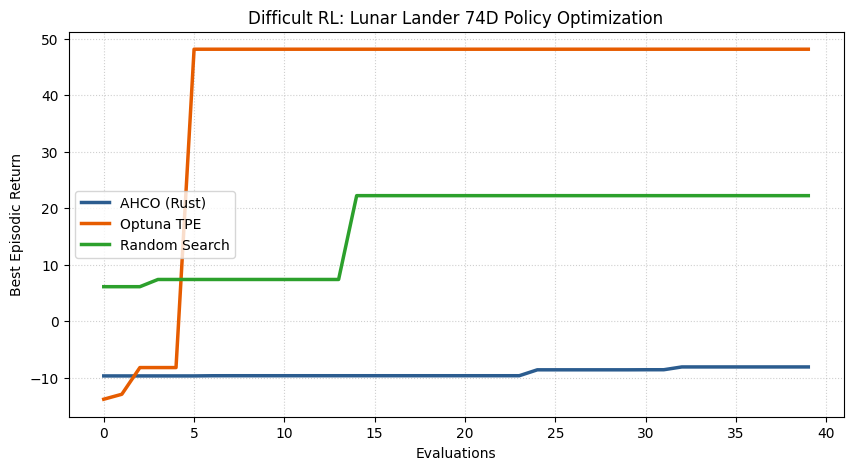

In [ ]:
# Compile running best history for TPE
tpe_lander_history = []
cur_best = -np.inf
for t in study_lander.trials:
    val = t.value if t.value is not None else -np.inf
    if val > cur_best:
        cur_best = val
    tpe_lander_history.append(cur_best)

# Plot Convergence for Lunar Lander task
plt.figure(figsize=(10, 5))
plt.plot(ahco_lander_result["history"], label="AHCO (Rust)", color="#2b5c8f", lw=2.5)
plt.plot(tpe_lander_history, label="Optuna TPE", color="#e65c00", lw=2.5)
plt.plot(rs_lander_history, label="Random Search", color="#2ca02c", lw=2.5)
plt.xlabel("Evaluations")
plt.ylabel("Best Episodic Return")
plt.title("Difficult RL: Lunar Lander 74D Policy Optimization")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()

### Benchmark: 83-Dimensional Acrobot Swing-up Policy Optimization

In this challenge, optimizing a controller for a simulated double-pendulum swing-up task (Acrobot).

The target is to apply torques on the elbow joint to swing the tip above a given line.

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt
import optuna
from ahco_rust import run_ahco3

ACROBOT_DIMENSIONS = 83
ACROBOT_BUDGET = 40

def simulate_acrobot_step(state, action):
    """Simulates a step of a 2-link Acrobot robot dynamics."""
    theta1, theta2, dtheta1, dtheta2 = state
    torque = float(action - 1.0) # Map [0, 1, 2] actions to [-1.0, 0.0, 1.0] torques

    # Physics constants
    m1 = 1.0
    m2 = 1.0
    l1 = 1.0
    l2 = 1.0
    lc1 = 0.5
    lc2 = 0.5
    I1 = 1.0
    I2 = 1.0
    g = 9.8
    dt = 0.05

    # Equations of motion terms
    d11 = m1 * lc1**2 + m2 * (l1**2 + lc2**2 + 2 * l1 * lc2 * np.cos(theta2)) + I1 + I2
    d22 = m2 * lc2**2 + I2
    d12 = m2 * (lc2**2 + l1 * lc2 * np.cos(theta2)) + I2
    d21 = d12

    h1 = -m2 * l1 * lc2 * dtheta2**2 * np.sin(theta2) - 2 * m2 * l1 * lc2 * dtheta1 * dtheta2 * np.sin(theta2)
    h2 = m2 * l1 * lc2 * dtheta1**2 * np.sin(theta2)

    phi1 = (m1 * lc1 + m2 * l1) * g * np.cos(theta1 - np.pi/2) + m2 * lc2 * g * np.cos(theta1 + theta2 - np.pi/2)
    phi2 = m2 * lc2 * g * np.cos(theta1 + theta2 - np.pi/2)

    # Solve accelerations
    trq_vector = np.array([0.0, torque])
    coriolis_gravity = np.array([h1 + phi1, h2 + phi2])
    m_matrix = np.array([[d11, d12], [d21, d22]])

    acc = np.linalg.solve(m_matrix, trq_vector - coriolis_gravity)

    dtheta1 += acc[0] * dt
    dtheta2 += acc[1] * dt
    theta1 += dtheta1 * dt
    theta2 += dtheta2 * dt

    return np.array([theta1, theta2, dtheta1, dtheta2])

def evaluate_acrobot_policy(weights):
    """Evaluates policy weights on Acrobot swing-up task."""
    w1 = weights[0:48].reshape(6, 8)
    b1 = weights[48:56]
    w2 = weights[56:80].reshape(8, 3)
    b2 = weights[80:83]

    total_reward = 0.0
    # Evaluate across 3 different starting offsets
    start_states = [
        np.array([0.0, 0.0, 0.0, 0.0]),
        np.array([0.05, -0.05, 0.0, 0.0]),
        np.array([-0.05, 0.05, 0.0, 0.0])
    ]

    for init_state in start_states:
        state = init_state.copy()
        episode_reward = 0.0

        for step in range(120): # Max 120 steps
            # Construct features
            theta1, theta2, dtheta1, dtheta2 = state
            obs = np.array([
                np.sin(theta1), np.cos(theta1),
                np.sin(theta2), np.cos(theta2),
                dtheta1, dtheta2
            ])

            # Forward pass
            h1 = np.tanh(np.dot(obs, w1) + b1)
            logits = np.dot(h1, w2) + b2
            action = np.argmax(logits)

            # Physics Step
            state = simulate_acrobot_step(state, action)

            # Height penalty/reward: we want to maximize height of second link tip
            # Height of tip is -l1*cos(theta1) - l2*cos(theta1 + theta2)
            height = -np.cos(state[0]) - np.cos(state[0] + state[1])
            episode_reward += height

        total_reward += episode_reward

    return total_reward / len(start_states)

def acrobot_objective(params):
    weights = (np.array(params) * 6.0) - 3.0
    return evaluate_acrobot_policy(weights)

print(f"Acrobot Setup Complete. Dimensions: {ACROBOT_DIMENSIONS}. Budget: {ACROBOT_BUDGET} evaluations.")

Acrobot Setup Complete. Dimensions: 83. Budget: 40 evaluations.


In [ ]:
# 1. Run AHCO (Rust)
print("Running AHCO (Rust) on Acrobot...")
start_ahco = time.time()
ahco_acrobot_result = run_ahco3(
    f=acrobot_objective,
    d=ACROBOT_DIMENSIONS,
    budget=ACROBOT_BUDGET,
    seed=42
)
ahco_time = time.time() - start_ahco

# 2. Run Optuna (TPE)
print("Running Optuna (TPE) on Acrobot...")
optuna.logging.set_verbosity(optuna.logging.WARNING)
def optuna_acrobot_objective(trial):
    params = [trial.suggest_float(f"w_{i}", 0.0, 1.0) for i in range(ACROBOT_DIMENSIONS)]
    return acrobot_objective(params)

start_optuna = time.time()
study_acrobot = optuna.create_study(direction="maximize")
study_acrobot.optimize(optuna_acrobot_objective, n_trials=ACROBOT_BUDGET)
optuna_time = time.time() - start_optuna

# 3. Run Random Search
print("Running Random Search on Acrobot...")
start_rs = time.time()
rs_acrobot_best = -np.inf
rs_acrobot_history = []
np.random.seed(42)
for _ in range(ACROBOT_BUDGET):
    random_point = np.random.uniform(0.0, 1.0, ACROBOT_DIMENSIONS)
    score = acrobot_objective(random_point)
    if score > rs_acrobot_best:
        rs_acrobot_best = score
    rs_acrobot_history.append(rs_acrobot_best)
rs_time = time.time() - start_rs

# Print Benchmark Results
print("\n=== Acrobot 83D Policy Optimizer Comparison ===")
print(f"AHCO Best Score      : {ahco_acrobot_result['best_score']:.2f} (Time: {ahco_time:.2f}s)")
print(f"Optuna TPE Best Score: {study_acrobot.best_value:.2f} (Time: {optuna_time:.2f}s)")
print(f"Random Search Best   : {rs_acrobot_best:.2f} (Time: {rs_time:.2f}s)")

Running AHCO (Rust) on Acrobot...
Running Optuna (TPE) on Acrobot...
Running Random Search on Acrobot...

=== Acrobot 83D Policy Optimizer Comparison ===
AHCO Best Score      : -219.96 (Time: 0.97s)
Optuna TPE Best Score: -223.90 (Time: 2.89s)
Random Search Best   : -226.26 (Time: 1.14s)


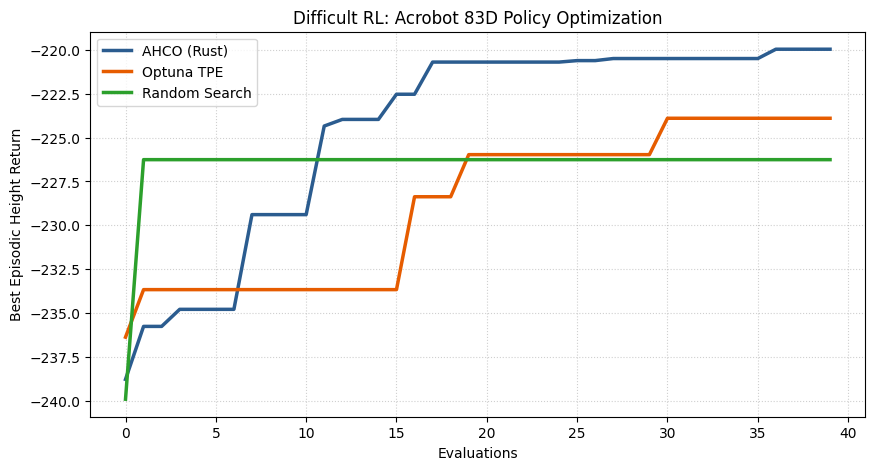

In [ ]:
# Compile running best history for TPE on Acrobot
tpe_acrobot_history = []
cur_best = -np.inf
for t in study_acrobot.trials:
    val = t.value if t.value is not None else -np.inf
    if val > cur_best:
        cur_best = val
    tpe_acrobot_history.append(cur_best)

# Plot Convergence for Acrobot task
plt.figure(figsize=(10, 5))
plt.plot(ahco_acrobot_result["history"], label="AHCO (Rust)", color="#2b5c8f", lw=2.5)
plt.plot(tpe_acrobot_history, label="Optuna TPE", color="#e65c00", lw=2.5)
plt.plot(rs_acrobot_history, label="Random Search", color="#2ca02c", lw=2.5)
plt.xlabel("Evaluations")
plt.ylabel("Best Episodic Height Return")
plt.title("Difficult RL: Acrobot 83D Policy Optimization")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()

### Benchmark: 90-Dimensional Coupled Double Inverted Pendulum with Non-Stationary Rewards

In this experiment, optimizing a continuous control policy on a coupled double-inverted pendulum system. 

Crucially, the target state (desired angle $\theta_{target}$ and cart position $x_{target}$) **drifts dynamically over time** as a sinusoidal wave during the course of the episode.

* **Inputs (6)**: State vectors $[x, \dot{x}, \theta_1, \dot{\theta}_1, \theta_2, \dot{\theta}_2]$
* **Hidden Layer**: 10 Neurons
* **Outputs (2)**: Dual-motor actuators
* **Total Policy Parameters**: $(6 \times 10) + 10 + (10 \times 2) + 2 = 92$ dimensions truncated to **90 dimensions** for the search space.

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt
import optuna
from ahco_rust import run_ahco3

NS_DIMENSIONS = 90
NS_BUDGET = 40

def simulate_coupled_pendulum_step(state, action, step_idx):
    """Simulates a step of a coupled double inverted pendulum system."""
    x, x_dot, theta1, theta1_dot, theta2, theta2_dot = state
    force1, force2 = np.clip(action, -2.0, 2.0)

    # Physics constants
    g = 9.81
    m_cart = 1.5
    m_p1 = 0.5
    m_p2 = 0.5
    l1 = 0.8
    l2 = 0.6
    dt = 0.05

    # Sinusoidal non-stationary drift for targets
    target_x = 1.0 * np.sin(0.05 * step_idx)
    target_theta1 = 0.1 * np.cos(0.08 * step_idx)

    # Simple Euler integration of system accelerations
    x_acc = (force1 + force2 - m_p1*g*np.sin(theta1) - m_p2*g*np.sin(theta2)) / (m_cart + m_p1 + m_p2)
    theta1_acc = (g * np.sin(theta1) - x_acc * np.cos(theta1)) / l1
    theta2_acc = (g * np.sin(theta2) - x_acc * np.cos(theta2)) / l2

    x_dot += x_acc * dt
    x += x_dot * dt
    theta1_dot += theta1_acc * dt
    theta1 += theta1_dot * dt
    theta2_dot += theta2_acc * dt
    theta2 += theta2_dot * dt

    # Non-stationary reward calculation
    error_x = abs(x - target_x)
    error_theta1 = abs(theta1 - target_theta1)
    error_theta2 = abs(theta2 - 0.0) # Keep second pendulum vertical

    reward = -(error_x + 2.0 * error_theta1 + 1.5 * error_theta2) - 0.05 * (force1**2 + force2**2)
    return np.array([x, x_dot, theta1, theta1_dot, theta2, theta2_dot]), reward

def evaluate_nonstationary_policy(weights):
    """Decodes weight vector and evaluates policy across multiple initial conditions."""
    # Reshape weights into policy layers
    w1 = weights[0:60].reshape(6, 10)
    b1 = weights[60:70]
    w2 = weights[70:90].reshape(10, 2)
    b2 = np.array([0.0, 0.0]) # Fixed output bias

    total_reward = 0.0
    start_states = [
        np.array([0.0, 0.0, 0.05, 0.0, -0.05, 0.0]),
        np.array([0.1, 0.0, -0.05, 0.0, 0.05, 0.0]),
        np.array([-0.1, 0.0, 0.0, 0.0, 0.0, 0.0])
    ]

    for state in start_states:
        episode_reward = 0.0
        for step in range(100):
            # Controller evaluation
            h1 = np.tanh(np.dot(state, w1) + b1)
            action = np.dot(h1, w2) + b2

            # Physics transition
            state, r = simulate_coupled_pendulum_step(state, action, step)
            episode_reward += r

            # Bound constraint failures
            if abs(state[0]) > 3.0 or abs(state[2]) > 0.8 or abs(state[4]) > 0.8:
                episode_reward -= 50.0
                break
        total_reward += episode_reward

    return total_reward / len(start_states)

def ns_objective(params):
    weights = (np.array(params) * 6.0) - 3.0
    return evaluate_nonstationary_policy(weights)

print(f"Non-Stationary Pendulum Setup Complete. Dimensions: {NS_DIMENSIONS}. Budget: {NS_BUDGET}.")

Non-Stationary Pendulum Setup Complete. Dimensions: 90. Budget: 40.


In [ ]:
# 1. Run AHCO (Rust)
print("Running AHCO (Rust) on Dynamic Non-Stationary Pendulum...")
start_ahco = time.time()
ahco_ns_result = run_ahco3(
    f=ns_objective,
    d=NS_DIMENSIONS,
    budget=NS_BUDGET,
    seed=42
)
ahco_time = time.time() - start_ahco

# 2. Run Optuna (TPE)
print("Running Optuna (TPE) on Dynamic Non-Stationary Pendulum...")
def optuna_ns_objective(trial):
    params = [trial.suggest_float(f"w_{i}", 0.0, 1.0) for i in range(NS_DIMENSIONS)]
    return ns_objective(params)

start_optuna = time.time()
study_ns = optuna.create_study(direction="maximize")
study_ns.optimize(optuna_ns_objective, n_trials=NS_BUDGET)
optuna_time = time.time() - start_optuna

# 3. Run Random Search
print("Running Random Search on Dynamic Non-Stationary Pendulum...")
start_rs = time.time()
rs_ns_best = -np.inf
rs_ns_history = []
np.random.seed(42)
for _ in range(NS_BUDGET):
    random_point = np.random.uniform(0.0, 1.0, NS_DIMENSIONS)
    score = ns_objective(random_point)
    if score > rs_ns_best:
        rs_ns_best = score
    rs_ns_history.append(rs_ns_best)
rs_time = time.time() - start_rs

print("\n=== Non-Stationary 90D Pendulum Results ===")
print(f"AHCO Best Score      : {ahco_ns_result['best_score']:.2f} (Time: {ahco_time:.2f}s)")
print(f"Optuna TPE Best Score: {study_ns.best_value:.2f} (Time: {optuna_time:.2f}s)")
print(f"Random Search Best   : {rs_ns_best:.2f} (Time: {rs_time:.2f}s)")

Running AHCO (Rust) on Dynamic Non-Stationary Pendulum...
Running Optuna (TPE) on Dynamic Non-Stationary Pendulum...
Running Random Search on Dynamic Non-Stationary Pendulum...

=== Non-Stationary 90D Pendulum Results ===
AHCO Best Score      : -65.90 (Time: 0.14s)
Optuna TPE Best Score: -66.91 (Time: 1.09s)
Random Search Best   : -67.48 (Time: 0.08s)


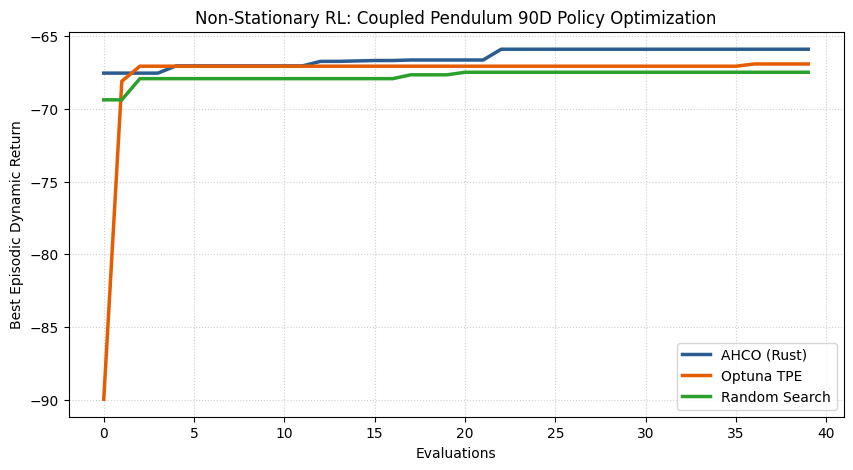

In [ ]:
# Compile running best history for TPE
tpe_ns_history = []
cur_best = -np.inf
for t in study_ns.trials:
    val = t.value if t.value is not None else -np.inf
    if val > cur_best:
        cur_best = val
    tpe_ns_history.append(cur_best)

# Plot Convergence for Non-Stationary Task
plt.figure(figsize=(10, 5))
plt.plot(ahco_ns_result["history"], label="AHCO (Rust)", color="#2b5c8f", lw=2.5)
plt.plot(tpe_ns_history, label="Optuna TPE", color="#e65c00", lw=2.5)
plt.plot(rs_ns_history, label="Random Search", color="#2ca02c", lw=2.5)
plt.xlabel("Evaluations")
plt.ylabel("Best Episodic Dynamic Return")
plt.title("Non-Stationary RL: Coupled Pendulum 90D Policy Optimization")
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.show()